# CONCH — Color-only reference distance

The analysis starts from public H&E image bytes, computes the reference-distance levels, evaluates the CONCH prompt ensemble, and checks the resulting performance curves.

## 1. Data source/acquisition

The CRC-VAL panel contains 7,180 image patches. The reference contains the first 200 images of each tissue class in the nine named NCT-CRC-HE-100K shards. Dataset and model revisions are fixed below; cached bytes are checked before reuse. The model repository requires its normal Hugging Face access approval.

Run this notebook in Python 3.11 with NumPy 2.4.6, Pandas 3.0.3, SciPy 1.16.2, scikit-learn 1.7.2, Pillow 12.1.1, PyArrow 17.0.0, PyTorch 2.5.0, torchvision 0.20.0, and the public CONCH source revision below. Install the notebook packages and the public CONCH dependencies before starting the kernel. Set CONCH_INPUTS and CONCH_SOURCE to reuse a verified local cache. GPU selection is controlled by CUDA_VISIBLE_DEVICES before kernel startup.

**Environment setup before starting the kernel (Linux/CUDA 12.4):**

```bash
python3.11 -m venv .venv-conch-primary
.venv-conch-primary/bin/python -m pip install torch==2.5.0 torchvision==0.20.0 --index-url https://download.pytorch.org/whl/cu124
.venv-conch-primary/bin/python -m pip install numpy==2.4.6 scipy==1.16.2 pandas==3.0.3 scikit-learn==1.7.2 Pillow==12.1.1 pyarrow==17.0.0 matplotlib==3.9.4 timm==0.9.16 transformers==4.40.1 tokenizers==0.19.1 huggingface-hub==0.23.5 ftfy==6.3.1 h5py==3.11.0 open_clip_torch==2.24.0 requests==2.32.3 nbformat==5.10.4 nbclient==0.10.4 nbconvert==7.16.6 ipykernel==6.29.5
.venv-conch-primary/bin/python -m ipykernel install --user --name conch-primary --display-name "conch-primary"
```

Select that kernel before Run All. The acquisition cell clones the pinned public CONCH implementation; every analysis-specific function remains inline below. Raw tiles are 224×224; the pinned public CONCH transform resizes model inputs to its default 448×448. The pixel-axis calculations use the raw-tile resolution.

In [1]:
AXIS_ID='test-02'
AXIS_TITLE='Color-only reference distance'
SELECTED_AXIS='nct_color_proximity'

from pathlib import Path
import os,sys,json,hashlib,io,subprocess,inspect
import numpy as np
import pandas as pd
import requests
import pyarrow.parquet as pq
from PIL import Image
from huggingface_hub import HfApi,hf_hub_download
from IPython.display import display,Image as DisplayImage
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,balanced_accuracy_score,f1_score
INPUTS=Path(os.environ.get('CONCH_INPUTS',str(Path.cwd()/'inputs'))).resolve()
OUTPUT=Path.cwd()/'computed'/AXIS_ID
SHARED=INPUTS/'inline_primary_predictions'
INPUTS.mkdir(parents=True,exist_ok=True);OUTPUT.mkdir(parents=True,exist_ok=True);SHARED.mkdir(parents=True,exist_ok=True)
REV='97765ecb14bf11ce7bb8779a1097d187844a67cb'
CODE_REV='141cc09c7d4ff33d8eda562bd75169b457f71a62'
MODEL_REV='f9ca9f877171a28ade80228fb195ac5d79003357'
MODEL_SHA='40a9644b9ba0e83a74576e0a5e5f7313599fa9c9cdaf3c20f8a3e271b0e9ae7c'
PROMPT_SHA='5cac7ab39a593e10d053647842401eae00b94351bd33c5edcad29b17757343e2'
LABEL_NAMES=dict(enumerate(['ADI','BACK','DEB','LYM','MUC','MUS','NORM','STR','TUM']))
LABELS=list(LABEL_NAMES)
def sha(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda:stream.read(8*1024*1024),b''):h.update(block)
    return h.hexdigest()
def display_figure(fig):
    stream=io.BytesIO();fig.savefig(stream,format='png',dpi=140,bbox_inches='tight')
    display(DisplayImage(data=stream.getvalue()));plt.close(fig)
SOURCE=Path(os.environ.get('CONCH_SOURCE',str(INPUTS.parent/'external'/'CONCH')))
if not (SOURCE/'.git').exists():
    SOURCE.parent.mkdir(parents=True,exist_ok=True)
    subprocess.run(['git','clone','https://github.com/mahmoodlab/CONCH.git',str(SOURCE)],check=True)
    subprocess.run(['git','-C',str(SOURCE),'checkout',CODE_REV],check=True)
assert subprocess.check_output(['git','-C',str(SOURCE),'rev-parse','HEAD'],text=True).strip()==CODE_REV
sys.path.insert(0,str(SOURCE))
PROMPTS=SOURCE/'prompts/crc100k_prompts_all_per_class.json'
assert sha(PROMPTS)==PROMPT_SHA
CHECKPOINT=INPUTS/'conch_checkpoint/pytorch_model.bin'
if not CHECKPOINT.exists():
    CHECKPOINT=Path(hf_hub_download('MahmoodLab/conch','pytorch_model.bin',revision=MODEL_REV,local_dir=INPUTS/'conch_checkpoint'))
assert CHECKPOINT.stat().st_size==802235437 and sha(CHECKPOINT)==MODEL_SHA
info=HfApi().dataset_info('1aurent/NCT-CRC-HE',revision=REV,files_metadata=True)
assert info.sha==REV
source_members={item.rfilename:item for item in info.siblings}
CRC_SHARDS=[
 'data/CRC_VAL_HE_7K-00000-of-00003-cce1097526b69125.parquet',
 'data/CRC_VAL_HE_7K-00001-of-00003-fbb5de8b1164f4ea.parquet',
 'data/CRC_VAL_HE_7K-00002-of-00003-2009e87e0c48fccf.parquet']
source_receipts=[]
for filename in CRC_SHARDS:
    path=INPUTS/'hf_parquet'/filename; expected=source_members[filename].lfs.sha256
    if not path.exists():path=Path(hf_hub_download('1aurent/NCT-CRC-HE',filename,repo_type='dataset',revision=REV,local_dir=INPUTS/'hf_parquet'))
    assert sha(path)==expected
    source_receipts.append(dict(filename=filename,revision=REV,sha256=expected,bytes=path.stat().st_size))

/ewsc/yektefai/spectra_runs/all_axes_inline_20261109/conch/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
class RangeFile(io.RawIOBase):
    def __init__(self, url):
        super().__init__()
        self.url, self.position, self.ranges, self.receipts = url, 0, [], []
        response = requests.get(url, headers={'Range': 'bytes=-8'}, timeout=60)
        response.raise_for_status()
        assert response.status_code == 206
        self.size = int(response.headers['Content-Range'].split('/')[-1])
        self.ranges.append((self.size - 8, response.content))

    def readable(self): return True
    def seekable(self): return True
    def tell(self): return self.position
    def seek(self, offset, whence=0):
        self.position = offset if whence == 0 else self.position + offset if whence == 1 else self.size + offset
        return self.position

    def read(self, size=-1):
        if size < 0: size = self.size - self.position
        size = min(size, self.size - self.position)
        start = self.position
        self.position += size
        if not size: return b''
        for offset, raw in self.ranges:
            if offset <= start and start + size <= offset + len(raw):
                return raw[start-offset:start-offset+size]
        assert size < 20_000_000, f'Unexpected bulk read: {size}'
        response = requests.get(self.url, headers={'Range': f'bytes={start}-{start+size-1}'}, timeout=120)
        response.raise_for_status()
        assert response.status_code == 206 and len(response.content) == size
        raw = response.content
        self.ranges.append((start, raw))
        self.receipts.append({'start': start, 'length': size, 'sha256': hashlib.sha256(raw).hexdigest(),
                              'content_range': response.headers.get('Content-Range')})
        return raw
LABEL_NAMES={0: 'ADI', 1: 'BACK', 2: 'DEB', 3: 'LYM', 4: 'MUC', 5: 'MUS', 6: 'NORM', 7: 'STR', 8: 'TUM'}
NCT_REFERENCE_SHARDS={2: 'data/NCT_CRC_HE_100K-00000-of-00031-9780c9afe3d80c58.parquet', 7: 'data/NCT_CRC_HE_100K-00004-of-00031-04197e7c2252e508.parquet', 0: 'data/NCT_CRC_HE_100K-00007-of-00031-7240d4f64e3ab056.parquet', 3: 'data/NCT_CRC_HE_100K-00011-of-00031-9586fd31243bcf81.parquet', 6: 'data/NCT_CRC_HE_100K-00014-of-00031-a59185824004206f.parquet', 8: 'data/NCT_CRC_HE_100K-00017-of-00031-240fc2989151d739.parquet', 1: 'data/NCT_CRC_HE_100K-00021-of-00031-e828a2a9aff921c7.parquet', 4: 'data/NCT_CRC_HE_100K-00025-of-00031-06d3e29beab848cc.parquet', 5: 'data/NCT_CRC_HE_100K-00027-of-00031-76ba1a4a6d60e4bf.parquet'}
reference_manifest=INPUTS/'PRIMARY_REFERENCE_IMAGE_MANIFEST.json'
if not reference_manifest.exists():
    ROOT=INPUTS;OUT=ROOT/'primary_reference_images';OUT.mkdir(parents=True,exist_ok=True)
    REV='97765ecb14bf11ce7bb8779a1097d187844a67cb';info=HfApi().dataset_info('1aurent/NCT-CRC-HE',revision=REV,files_metadata=True);members={x.rfilename:x for x in info.siblings};identities=[];sources=[]
    for label,shard in sorted(NCT_REFERENCE_SHARDS.items()):
     cls=LABEL_NAMES[label];url='https://huggingface.co/datasets/1aurent/NCT-CRC-HE/resolve/'+REV+'/'+shard;stream=RangeFile(url);p=pq.ParquetFile(stream);offset=0;taken=0
     for group in range(p.metadata.num_row_groups):
      labels=p.read_row_group(group,columns=['label']).column('label').to_pylist()
      if label in labels:
       for row_i,example in enumerate(p.read_row_group(group,columns=['image','label']).to_pylist()):
        if int(example['label'])!=label:continue
        sample=f'nctref_{cls}_{taken:04d}';encoded=example['image']['bytes'];name=example['image'].get('path') or sample+'.png';target=OUT/(sample+Path(name).suffix);target.write_bytes(encoded)
        identities.append({'sample_id':sample,'label':label,'label_name':cls,'source_record_index':taken,'shard':shard,'parquet_row_index':offset+row_i,'path':str(target),'source_image_path':name,'bytes':len(encoded),'sha256':hashlib.sha256(encoded).hexdigest()});taken+=1
        if taken==200:break
      offset+=len(labels)
      if taken==200:break
     assert taken==200
     source=members[shard];sources.append({'url':url,'filename':shard,'revision':REV,'full_file_bytes':source.size,'full_file_sha256':source.lfs.sha256,'full_file_hash_verified':False,'ranges':stream.receipts})
     print(cls,taken,sum(x['length'] for x in stream.receipts),flush=True)
    assert len(identities)==1800
    (ROOT/'PRIMARY_REFERENCE_IMAGE_MANIFEST.json').write_text(json.dumps({'completed':True,'selection':'first200matchinglabelrowsinexactclassshard','images':identities,'sources':sources,'count':len(identities)},indent=2))

reference_manifest_data=json.loads(reference_manifest.read_text())
assert reference_manifest_data['count']==1800
for row in reference_manifest_data['images']:
    # Paths remain portable when the cache is moved.
    row['path']=str(INPUTS/'primary_reference_images'/Path(row['path']).name)
    assert sha(row['path'])==row['sha256']
assert all(s['revision']==REV for s in reference_manifest_data['sources'])
print('Verified public inputs:',len(source_receipts),'CRC shards and',len(reference_manifest_data['images']),'reference images')

Verified public inputs: 3 CRC shards and 1800 reference images


## 2. Data processing

Decode every image and compute RGB/HSV summaries, intensity histograms, tissue fractions, and edge/entropy statistics. Features use 224×224 RGB images and are calculated without model scores. The reference remains class-balanced.

In [3]:
def rgb_to_hsv(arr: np.ndarray) -> np.ndarray:
    r = arr[..., 0]
    g = arr[..., 1]
    b = arr[..., 2]
    mx = np.maximum(np.maximum(r, g), b)
    mn = np.minimum(np.minimum(r, g), b)
    diff = mx - mn

    h = np.zeros_like(mx)
    mask = diff > 1e-8
    rmask = mask & (mx == r)
    gmask = mask & (mx == g)
    bmask = mask & (mx == b)
    h[rmask] = ((g[rmask] - b[rmask]) / diff[rmask]) % 6.0
    h[gmask] = ((b[gmask] - r[gmask]) / diff[gmask]) + 2.0
    h[bmask] = ((r[bmask] - g[bmask]) / diff[bmask]) + 4.0
    h /= 6.0

    s = np.zeros_like(mx)
    nonzero = mx > 1e-8
    s[nonzero] = diff[nonzero] / mx[nonzero]
    v = mx
    return np.stack([h, s, v], axis=-1)

def normalized_hist(values: np.ndarray, bins: int, value_range: tuple[float, float]) -> np.ndarray:
    hist, _ = np.histogram(values.reshape(-1), bins=bins, range=value_range)
    hist = hist.astype(np.float32)
    total = float(hist.sum())
    if total > 0:
        hist /= total
    return hist

def dhash64(gray: np.ndarray) -> str:
    pil = Image.fromarray(np.uint8(np.clip(gray * 255.0, 0, 255)))
    small = pil.resize((9, 8), Image.Resampling.BILINEAR)
    vals = np.asarray(small, dtype=np.int16)
    bits = vals[:, 1:] > vals[:, :-1]
    out = 0
    for bit in bits.reshape(-1):
        out = (out << 1) | int(bit)
    return f"{out:016x}"

def image_features(image: Image.Image, raw_bytes: bytes | None = None) -> dict[str, float | str]:
    img = image.convert("RGB")
    if img.size != (224, 224):
        img = img.resize((224, 224), Image.Resampling.BICUBIC)
    arr_u8 = np.asarray(img, dtype=np.uint8)
    arr = arr_u8.astype(np.float32) / 255.0
    hsv = rgb_to_hsv(arr)
    gray = 0.299 * arr[..., 0] + 0.587 * arr[..., 1] + 0.114 * arr[..., 2]
    sat = hsv[..., 1]
    value = hsv[..., 2]

    dx = np.diff(gray, axis=1)
    dy = np.diff(gray, axis=0)
    edge = np.sqrt(dx[:-1, :] ** 2 + dy[:, :-1] ** 2)

    gray_hist = normalized_hist(gray, 16, (0.0, 1.0))
    entropy = -float(np.sum(gray_hist * np.log2(gray_hist + 1e-12)))

    feats: dict[str, float | str] = {}
    if raw_bytes is None:
        raw_bytes = arr_u8.tobytes()
    feats["image_md5"] = hashlib.md5(raw_bytes).hexdigest()
    feats["dhash64"] = dhash64(gray)

    for i, name in enumerate(("r", "g", "b")):
        channel = arr[..., i]
        feats[f"{name}_mean"] = float(channel.mean())
        feats[f"{name}_std"] = float(channel.std())
        feats[f"{name}_p05"] = float(np.quantile(channel, 0.05))
        feats[f"{name}_p95"] = float(np.quantile(channel, 0.95))
    for i, name in enumerate(("h", "s", "v")):
        channel = hsv[..., i]
        feats[f"{name}_mean"] = float(channel.mean())
        feats[f"{name}_std"] = float(channel.std())
    for i, val in enumerate(normalized_hist(hsv[..., 0], 8, (0.0, 1.0))):
        feats[f"h_hist_{i:02d}"] = float(val)
    for i, val in enumerate(normalized_hist(sat, 8, (0.0, 1.0))):
        feats[f"s_hist_{i:02d}"] = float(val)
    for i, val in enumerate(normalized_hist(value, 8, (0.0, 1.0))):
        feats[f"v_hist_{i:02d}"] = float(val)
    for i, val in enumerate(gray_hist):
        feats[f"gray_hist_{i:02d}"] = float(val)

    feats["gray_mean"] = float(gray.mean())
    feats["gray_std"] = float(gray.std())
    feats["gray_entropy"] = entropy
    feats["edge_mean"] = float(edge.mean())
    feats["edge_std"] = float(edge.std())
    feats["tissue_fraction"] = float(((gray < 0.90) & (sat > 0.05)).mean())
    feats["white_fraction"] = float(((gray > 0.90) & (sat < 0.15)).mean())
    feats["dark_fraction"] = float((gray < 0.20).mean())
    feats["saturation_high_fraction"] = float((sat > 0.50).mean())
    return feats

def iter_crc_val(parquet_dir: Path):
    idx = 0
    for parquet_path in sorted(parquet_dir.glob("CRC_VAL_HE_7K-*.parquet")):
        pf = pq.ParquetFile(parquet_path)
        for rg in range(pf.num_row_groups):
            table = pf.read_row_group(rg, columns=["image", "label"])
            labels = table["label"].to_pylist()
            images = table["image"].to_pylist()
            for label, img_struct in zip(labels, images):
                raw = img_struct["bytes"]
                path = img_struct.get("path") or ""
                image = Image.open(io.BytesIO(raw))
                yield {
                    "source_split": "CRC_VAL_HE_7K",
                    "source_record_index": idx,
                    "sample_id": f"crcval_{idx:05d}",
                    "image_path": path,
                    "label": int(label),
                    "label_name": LABEL_NAMES[int(label)],
                    "image": image,
                    "raw_bytes": raw,
                }
                idx += 1

def build_crc_features(parquet_dir: Path) -> pd.DataFrame:
    rows = []
    for rec in iter_crc_val(parquet_dir):
        feats = image_features(rec["image"], rec["raw_bytes"])
        rows.append({k: v for k, v in rec.items() if k not in {"image", "raw_bytes"}} | feats)
    return pd.DataFrame(rows)

crc_features=build_crc_features(INPUTS/'hf_parquet/data')
reference_rows=[]
for row in reference_manifest_data['images']:
    with Image.open(row['path']) as image:
        values=image_features(image)
    reference_rows.append(dict(source_split='NCT_CRC_HE_100K_reference',source_record_index=row['source_record_index'],sample_id=row['sample_id'],image_path='',label=row['label'],label_name=row['label_name'],reference_shard=row['shard'],**values))
reference_features=pd.DataFrame(reference_rows)
all_features=pd.concat([crc_features,reference_features],ignore_index=True)
assert len(crc_features)==7180 and len(reference_features)==1800
all_features.to_csv(OUTPUT/'pixel_features.csv',index=False)
display(all_features.groupby(['source_split','label_name']).size().unstack(fill_value=0))
print('Pixel features recomputed for',len(all_features),'images')

label_name,ADI,BACK,DEB,LYM,MUC,MUS,NORM,STR,TUM
source_split,,,,,,,,,
CRC_VAL_HE_7K,1338,847,339,634,1035,592,741,421,1233
NCT_CRC_HE_100K_reference,200,200,200,200,200,200,200,200,200


Pixel features recomputed for 8980 images


## 3. Axis definition and level construction

Standardize joint and color features using the reference mean and population standard deviation. The joint and color distances average the 20 nearest reference distances. Texture and tissue-fraction candidates use Euclidean distance from the corresponding reference median. Negate distance so larger values mean greater similarity, then assign six equal-frequency levels by decreasing similarity. Level 1 is closest to the reference. Class composition and fixed classifiers are controls on these same levels.

In [4]:
FEATURE_EXCLUDE={'sample_id', 'source_record_index', 'image_path', 'dhash64', 'label_name', 'source_split', 'image_md5', 'reference_shard', 'label'}
def feature_columns(df: pd.DataFrame) -> list[str]:
    cols = []
    for col in df.columns:
        if col in FEATURE_EXCLUDE:
            continue
        if pd.api.types.is_numeric_dtype(df[col]):
            cols.append(col)
    return cols

def zscore(train: np.ndarray, test: np.ndarray) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    mu = train.mean(axis=0)
    sd = train.std(axis=0)
    sd[sd < 1e-6] = 1.0
    return (train - mu) / sd, (test - mu) / sd, mu, sd

def mean_knn_distance(test: np.ndarray, ref: np.ndarray, k: int = 20, chunk: int = 512) -> np.ndarray:
    k = min(k, ref.shape[0])
    out = np.empty(test.shape[0], dtype=np.float32)
    ref_sq = np.sum(ref * ref, axis=1)[None, :]
    for start in range(0, test.shape[0], chunk):
        x = test[start : start + chunk]
        d2 = np.sum(x * x, axis=1)[:, None] + ref_sq - 2.0 * (x @ ref.T)
        d2 = np.maximum(d2, 0.0)
        part = np.partition(np.sqrt(d2), kth=k - 1, axis=1)[:, :k]
        out[start : start + chunk] = part.mean(axis=1)
    return out

def assign_similarity_levels(values: pd.Series, n_levels: int) -> tuple[pd.Series, list[float]]:
    """Assign 1=highest similarity through n=lowest similarity by quantile."""
    ranks = values.rank(method="first", ascending=False)
    levels = pd.qcut(ranks, q=n_levels, labels=False) + 1
    quantiles = [float(values.quantile(q)) for q in np.linspace(0, 1, n_levels + 1)]
    return levels.astype(int), quantiles

def level_summary(df: pd.DataFrame, axis_col: str, level_col: str) -> list[dict]:
    rows = []
    for level, part in df.groupby(level_col, sort=True):
        label_counts = part["label_name"].value_counts().sort_index().to_dict()
        rows.append(
            {
                "level": int(level),
                "n": int(len(part)),
                "axis_mean": float(part[axis_col].mean()),
                "axis_min": float(part[axis_col].min()),
                "axis_max": float(part[axis_col].max()),
                "label_counts": {str(k): int(v) for k, v in label_counts.items()},
            }
        )
    return rows

cols_all=feature_columns(all_features)
color_cols=[c for c in cols_all if c.startswith(('r_','g_','b_','h_','s_','v_','gray_hist_','gray_mean','gray_std'))]
tissue_cols=['tissue_fraction','white_fraction','dark_fraction','saturation_high_fraction']
texture_cols=['gray_entropy','edge_mean','edge_std','gray_std']
crc=crc_features.copy();ref=reference_features.copy()
ref_z,crc_z,_,_=zscore(ref[cols_all].to_numpy(np.float32),crc[cols_all].to_numpy(np.float32))
ref_color_z,crc_color_z,_,_=zscore(ref[color_cols].to_numpy(np.float32),crc[color_cols].to_numpy(np.float32))
crc['axis_nct_color_texture_similarity']=-mean_knn_distance(crc_z,ref_z,k=20)
crc['axis_nct_color_similarity']=-mean_knn_distance(crc_color_z,ref_color_z,k=20)
crc['axis_nct_tissue_fraction_similarity']=-np.sqrt(((crc[tissue_cols]-ref[tissue_cols].median())**2).sum(axis=1))
crc['axis_nct_texture_complexity_similarity']=-np.sqrt(((crc[texture_cols]-ref[texture_cols].median())**2).sum(axis=1))
axes={
 'nct_color_texture_proximity':dict(axis_col='axis_nct_color_texture_similarity',level_col='level_nct_color_texture_proximity'),
 'nct_color_proximity':dict(axis_col='axis_nct_color_similarity',level_col='level_nct_color_proximity'),
 'nct_tissue_fraction_proximity':dict(axis_col='axis_nct_tissue_fraction_similarity',level_col='level_nct_tissue_fraction_proximity'),
 'nct_texture_complexity_proximity':dict(axis_col='axis_nct_texture_complexity_similarity',level_col='level_nct_texture_complexity_proximity')}
for name,spec in axes.items():
    crc[spec['level_col']],spec['quantiles']=assign_similarity_levels(crc[spec['axis_col']],6)
crc.to_csv(OUTPUT/'axis_membership.csv',index=False)
axis_spec=axes[SELECTED_AXIS]
display(pd.DataFrame(level_summary(crc,axis_spec['axis_col'],axis_spec['level_col'])))

,level,n,axis_mean,axis_min,axis_max,label_counts
0,1,1197,-1.776312,-2.014312,-1.213220,"{'ADI': 5, 'BACK': 1, 'DEB': 63, 'LYM': 136, '..."
1,2,1197,-2.209825,-2.424051,-2.015375,"{'ADI': 31, 'BACK': 19, 'DEB': 51, 'LYM': 80, ..."
2,3,1196,-2.698132,-3.026762,-2.424115,"{'ADI': 56, 'BACK': 26, 'DEB': 28, 'LYM': 95, ..."
3,4,1197,-3.393497,-3.802840,-3.027137,"{'ADI': 438, 'BACK': 53, 'DEB': 13, 'LYM': 85,..."
4,5,1196,-4.380153,-5.290449,-3.803376,"{'ADI': 435, 'BACK': 298, 'DEB': 5, 'LYM': 194..."
5,6,1197,-33.344448,-663.742798,-5.309136,"{'ADI': 373, 'BACK': 450, 'DEB': 179, 'LYM': 4..."


## 4. Model results or released scores

Load the fixed CONCH checkpoint and CRC prompt ensemble. Encode every CRC image with the public preprocessing transform and float32 model, calculate cosine logits against the averaged text classifier, and classify by the largest logit. No audit-specific fine-tuning is performed. These six analyses share one set of predictions; reuse requires matching raw-source, checkpoint, prompt, code, method and output hashes. Missing or changed predictions trigger inference in these cells.

In [5]:
def load_crc_prompts(path: Path):
    obj = json.loads(path.read_text())
    prompt_set = obj["0"]
    cn = prompt_set["classnames"]
    classnames = [cn[LABEL_NAMES[i]] for i in range(len(LABEL_NAMES))]
    return classnames, prompt_set["templates"]

import torch
import torch.nn.functional as F
from conch.downstream.zeroshot_path import zero_shot_classifier
from conch.open_clip_custom import create_model_from_pretrained
torch.set_num_threads(2)
def score_crc():
    device=torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
    model,preprocess=create_model_from_pretrained('conch_ViT-B-16',checkpoint_path=str(CHECKPOINT),device=device)
    model.eval()
    classnames,templates=load_crc_prompts(PROMPTS)
    with torch.inference_mode():classifier=zero_shot_classifier(model,classnames,templates,device=device)
    logit_scale=float(model.logit_scale.exp().detach().cpu().item())
    rows=[];images=[];metadata=[]
    def flush():
        if not images:return
        with torch.inference_mode():
            encoded=model.encode_image(torch.stack(images).to(device))
            logits=encoded@classifier;probs=F.softmax(logits*logit_scale,dim=1);pred=logits.argmax(dim=1)
        for item,lg,pr,y in zip(metadata,logits.cpu().numpy(),probs.cpu().numpy(),pred.cpu().numpy()):
            output={k:v for k,v in item.items() if k not in ['image','raw_bytes','source_split']}
            output.update(pred=int(y),pred_label_name=LABEL_NAMES[int(y)],correct=int(y==item['label']))
            output.update({f'logit_{LABEL_NAMES[j]}':float(lg[j]) for j in LABELS})
            output.update({f'prob_{LABEL_NAMES[j]}':float(pr[j]) for j in LABELS});rows.append(output)
        images.clear();metadata.clear()
    for item in iter_crc_val(INPUTS/'hf_parquet/data'):
        expected=crc.iloc[len(rows)+len(images)]
        assert item['sample_id']==expected['sample_id'] and item['label']==expected['label']
        images.append(preprocess(item['image']));metadata.append(item)
        if len(images)==128:flush()
    flush();result=pd.DataFrame(rows)
    assert len(result)==7180
    del model,classifier
    if torch.cuda.is_available():torch.cuda.empty_cache()
    return result

prediction_path=SHARED/'crc_predictions.csv';receipt_path=SHARED/'crc_prediction_receipt.json'
method_sha=hashlib.sha256((inspect.getsource(score_crc)+inspect.getsource(iter_crc_val)+inspect.getsource(load_crc_prompts)).encode()).hexdigest()
prediction_inputs=dict(data=source_receipts,checkpoint_sha256=MODEL_SHA,prompt_sha256=PROMPT_SHA,public_code_revision=CODE_REV,method_sha256=method_sha,precision='float32',batch_size=128)
valid=False
if receipt_path.exists() and prediction_path.exists():
    receipt=json.loads(receipt_path.read_text());valid=receipt['inputs']==prediction_inputs and receipt['output_sha256']==sha(prediction_path)
if valid:
    predictions=pd.read_csv(prediction_path);prediction_stage='verified reuse of shared predictions generated by these cells'
else:
    predictions=score_crc();predictions.to_csv(prediction_path,index=False)
    receipt_path.write_text(json.dumps(dict(inputs=prediction_inputs,output_sha256=sha(prediction_path),n=len(predictions)),indent=2));prediction_stage='fresh model inference'
assert len(predictions)==7180 and not predictions['sample_id'].duplicated().any()
print(prediction_stage)
display(predictions.groupby('label_name')['correct'].agg(['count','mean']))

verified reuse of shared predictions generated by these cells


,count,mean
label_name,,
ADI,1338,0.866966
BACK,847,0.945691
DEB,339,0.684366
LYM,634,0.993691
MUC,1035,0.909179
MUS,592,0.891892
NORM,741,0.519568
STR,421,0.439430
TUM,1233,0.556367


## 5. Curves and controls

Calculate balanced accuracy, accuracy and F1 by level, class-adjusted correctness, and macro recall over classes supported by at least 10 images at every level. Fit nearest-centroid and logistic classifiers once on the reference pixel features and evaluate them on every level. The class-composition plot makes changing tissue mixtures visible.

/ewsc/yektefai/spectra_runs/all_axes_inline_20261109/conch/.venv-primary/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


/ewsc/yektefai/spectra_runs/all_axes_inline_20261109/conch/.venv-primary/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


/ewsc/yektefai/spectra_runs/all_axes_inline_20261109/conch/.venv-primary/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/ewsc/yektefai/spectra_runs/all_axes_inline_20261109/conch/.venv-primary/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/ewsc/yektefai/spectra_runs/all_axes_inline_20261109/conch/.venv-primary/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/ewsc/yektefai/spectra_runs/all_axes_inline_20261109/conch/.venv-primary/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_tru

/ewsc/yektefai/spectra_runs/all_axes_inline_20261109/conch/.venv-primary/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/ewsc/yektefai/spectra_runs/all_axes_inline_20261109/conch/.venv-primary/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/ewsc/yektefai/spectra_runs/all_axes_inline_20261109/conch/.venv-primary/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/ewsc/yektefai/spectra_runs/all_axes_inline_20261109/conch/.venv-primary/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_tru

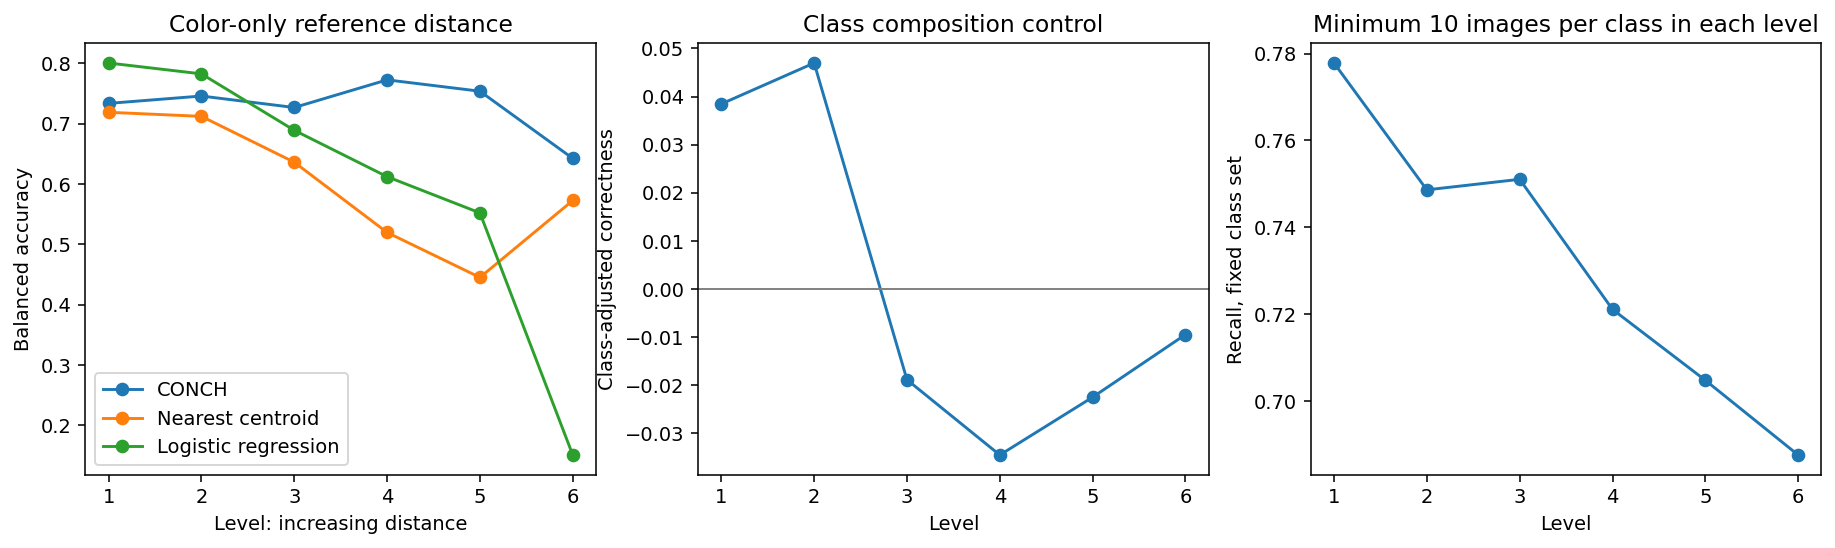

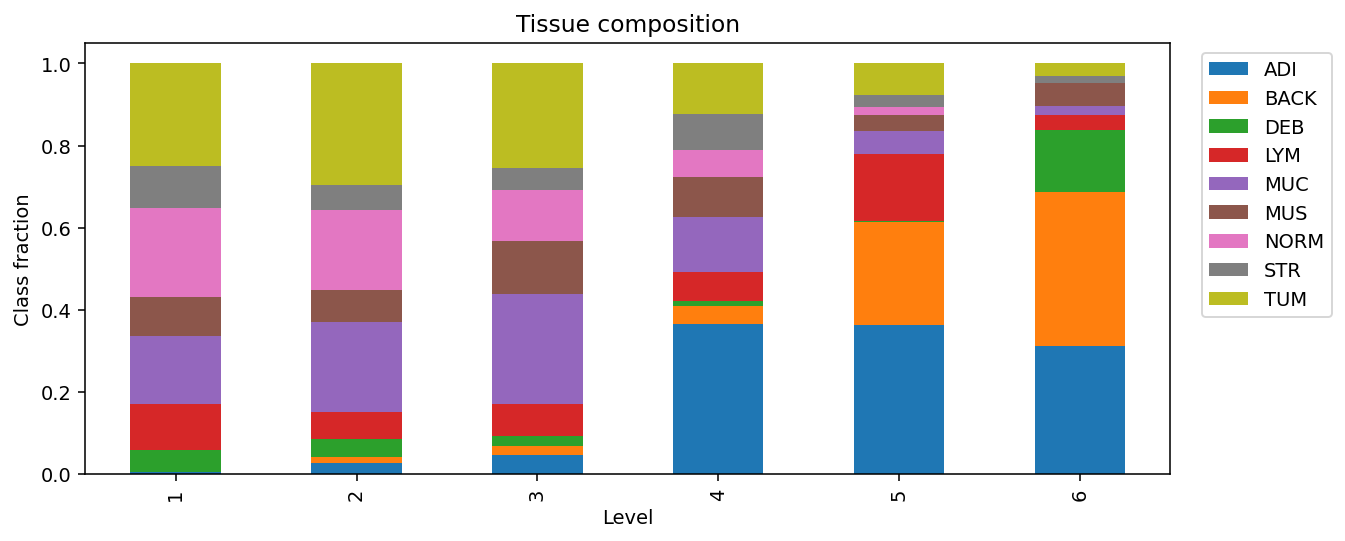

,level,n,axis_mean,accuracy,balanced_accuracy,macro_f1,weighted_f1
0,1,1197,-1.776312,0.723475,0.733414,0.619687,0.742227
1,2,1197,-2.209825,0.741855,0.745579,0.659444,0.770636
2,3,1196,-2.698132,0.724916,0.726584,0.655128,0.748429
3,4,1197,-3.393497,0.752715,0.772368,0.723526,0.779334
4,5,1196,-4.380153,0.843645,0.753557,0.690567,0.834033
5,6,1197,-33.344448,0.849624,0.642218,0.656309,0.827604


,level,n,mean_class_adjusted_correct_residual
0,1,1197,0.038463
1,2,1197,0.046977
2,3,1196,-0.018897
3,4,1197,-0.034553
4,5,1196,-0.022526
5,6,1197,-0.009498


,level,stable_class_macro_recall,stable_classes,supports
0,1,0.777837,"[LYM, MUC, MUS, STR, TUM]","{'LYM': 136, 'MUC': 198, 'MUS': 114, 'STR': 12..."
1,2,0.748606,"[LYM, MUC, MUS, STR, TUM]","{'LYM': 80, 'MUC': 261, 'MUS': 96, 'STR': 73, ..."
2,3,0.751034,"[LYM, MUC, MUS, STR, TUM]","{'LYM': 95, 'MUC': 321, 'MUS': 153, 'STR': 65,..."
3,4,0.721062,"[LYM, MUC, MUS, STR, TUM]","{'LYM': 85, 'MUC': 159, 'MUS': 119, 'STR': 105..."
4,5,0.704715,"[LYM, MUC, MUS, STR, TUM]","{'LYM': 194, 'MUC': 68, 'MUS': 45, 'STR': 37, ..."
5,6,0.687497,"[LYM, MUC, MUS, STR, TUM]","{'LYM': 44, 'MUC': 28, 'MUS': 65, 'STR': 21, '..."


,accuracy,balanced_accuracy,macro_f1,weighted_f1
CONCH,0.772702,0.756350,0.744796,0.774093
Nearest centroid,0.689833,0.602062,0.603468,0.686456
Logistic regression,0.669499,0.618660,0.618293,0.680805


58570

In [6]:
def nearest_centroid_predict(x_train: np.ndarray, y_train: np.ndarray, x_test: np.ndarray) -> np.ndarray:
    centroids = []
    for lab in LABELS:
        centroids.append(x_train[y_train == lab].mean(axis=0))
    centroids = np.vstack(centroids)
    d2 = ((x_test[:, None, :] - centroids[None, :, :]) ** 2).sum(axis=2)
    return d2.argmin(axis=1)

def metrics(y_true: np.ndarray, y_pred: np.ndarray) -> dict[str, float]:
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
        "macro_f1": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
        "weighted_f1": float(f1_score(y_true, y_pred, average="weighted", zero_division=0)),
    }

def metric_by_level(df: pd.DataFrame, level_col: str, pred_col: str) -> list[dict]:
    rows = []
    for level, part in df.groupby(level_col, sort=True):
        y = part["label"].to_numpy()
        p = part[pred_col].to_numpy()
        m = metrics(y, p)
        row = {
            "level": int(level),
            "n": int(len(part)),
            "axis_mean": float(part[df.attrs["axis_col"]].mean()),
            **m,
            "label_counts": {str(k): int(v) for k, v in part["label_name"].value_counts().sort_index().to_dict().items()},
        }
        rows.append(row)
    return rows

def per_class_recalls(df: pd.DataFrame, level_col: str, pred_col: str) -> list[dict]:
    rows = []
    for level, part in df.groupby(level_col, sort=True):
        for lab in LABELS:
            sub = part[part["label"] == lab]
            if len(sub) == 0:
                recall = np.nan
            else:
                recall = float((sub[pred_col] == lab).mean())
            rows.append({"level": int(level), "label": lab, "label_name": LABEL_NAMES[lab], "n": int(len(sub)), "recall": recall})
    return rows

def class_adjusted_residual_by_level(df: pd.DataFrame, level_col: str, pred_col: str) -> list[dict]:
    correct = (df[pred_col].to_numpy() == df["label"].to_numpy()).astype(float)
    tmp = df[["label", level_col]].copy()
    tmp["correct"] = correct
    class_mean = tmp.groupby("label")["correct"].transform("mean")
    tmp["residual"] = tmp["correct"] - class_mean
    rows = []
    for level, part in tmp.groupby(level_col, sort=True):
        rows.append(
            {
                "level": int(level),
                "n": int(len(part)),
                "mean_class_adjusted_correct_residual": float(part["residual"].mean()),
            }
        )
    return rows

def stable_class_macro(df: pd.DataFrame, level_col: str, pred_col: str, min_support: int = 10) -> dict:
    stable = []
    for lab in LABELS:
        supports = [int(((df[level_col] == level) & (df["label"] == lab)).sum()) for level in sorted(df[level_col].unique())]
        if min(supports) >= min_support:
            stable.append(lab)
    rows = []
    for level, part in df.groupby(level_col, sort=True):
        recalls = []
        supports = {}
        for lab in stable:
            sub = part[part["label"] == lab]
            supports[LABEL_NAMES[lab]] = int(len(sub))
            recalls.append(float((sub[pred_col] == lab).mean()))
        rows.append(
            {
                "level": int(level),
                "stable_class_macro_recall": float(np.mean(recalls)) if recalls else float("nan"),
                "stable_classes": [LABEL_NAMES[x] for x in stable],
                "supports": supports,
            }
        )
    return {"min_support": min_support, "stable_classes": [LABEL_NAMES[x] for x in stable], "rows": rows}

def assign_deciles(df: pd.DataFrame, axis_col: str) -> pd.Series:
    ranks = df[axis_col].rank(method="first", ascending=False)
    return (pd.qcut(ranks, q=10, labels=False) + 1).astype(int)

def summarize_axis(df: pd.DataFrame, axis_name: str, spec: dict, out_dir: Path) -> dict:
    axis_col = spec["axis_col"]
    level_col = spec["level_col"]
    df = df.copy()
    df.attrs["axis_col"] = axis_col

    target_rows = metric_by_level(df, level_col, "pred")
    centroid_rows = metric_by_level(df, level_col, "baseline_centroid_pred")
    logistic_rows = metric_by_level(df, level_col, "baseline_logistic_pred")
    residual_rows = class_adjusted_residual_by_level(df, level_col, "pred")
    stable_macro = stable_class_macro(df, level_col, "pred", min_support=10)
    target_bacc = [r["balanced_accuracy"] for r in target_rows]
    target_acc = [r["accuracy"] for r in target_rows]
    levels = [r["level"] for r in target_rows]
    rho_bacc = spearmanr(levels, target_bacc).statistic
    rho_acc = spearmanr(levels, target_acc).statistic

    recall_rows = per_class_recalls(df, level_col, "pred")
    pd.DataFrame(recall_rows).to_csv(out_dir / f"{axis_name}_per_class_recalls.csv", index=False)

    decile_summary = None
    if axis_name == "nct_color_texture_proximity":
        decile_col = "level_nct_color_texture_decile"
        df[decile_col] = assign_deciles(df, axis_col)
        df.attrs["axis_col"] = axis_col
        decile_summary = {
            "target": metric_by_level(df, decile_col, "pred"),
            "class_adjusted_residual": class_adjusted_residual_by_level(df, decile_col, "pred"),
            "stable_class_macro_min_support_5": stable_class_macro(df, decile_col, "pred", min_support=5),
        }
        df[["sample_id", axis_col, decile_col]].to_csv(out_dir / "nct_color_texture_decile_assignments.csv", index=False)

    return {
        "axis_col": axis_col,
        "level_col": level_col,
        "target_by_level": target_rows,
        "baseline_centroid_by_level": centroid_rows,
        "baseline_logistic_by_level": logistic_rows,
        "class_adjusted_residual_by_level": residual_rows,
        "stable_class_macro_min_support_10": stable_macro,
        "spearman_level_vs_target_bacc": float(rho_bacc),
        "spearman_level_vs_target_acc": float(rho_acc),
        "decile_densification": decile_summary,
    }

merged=crc.merge(predictions,on=['sample_id','image_path','label','label_name'],how='inner',validate='one_to_one',suffixes=('','_score'))
assert len(merged)==len(crc)
scaler=StandardScaler();xtrain=scaler.fit_transform(ref[cols_all].to_numpy(np.float32));xtest=scaler.transform(merged[cols_all].to_numpy(np.float32));ytrain=ref['label'].to_numpy()
merged['baseline_centroid_pred']=nearest_centroid_predict(xtrain,ytrain,xtest)
logistic=LogisticRegression(max_iter=1000,C=1.0,multi_class='auto',solver='lbfgs',random_state=0)
logistic.fit(xtrain,ytrain);merged['baseline_logistic_pred']=logistic.predict(xtest)
summary={name:summarize_axis(merged,name,spec,OUTPUT) for name,spec in axes.items()}
selected=summary[SELECTED_AXIS]
curves=pd.DataFrame(selected['target_by_level']);residuals=pd.DataFrame(selected['class_adjusted_residual_by_level']);stable=pd.DataFrame(selected['stable_class_macro_min_support_10']['rows'])
fig,axs=plt.subplots(1,3,figsize=(16,4))
for key,label in [('target_by_level','CONCH'),('baseline_centroid_by_level','Nearest centroid'),('baseline_logistic_by_level','Logistic regression')]:
    rows=pd.DataFrame(selected[key]);axs[0].plot(rows.level,rows.balanced_accuracy,'o-',label=label)
axs[0].set(xlabel='Level: increasing distance',ylabel='Balanced accuracy',title=AXIS_TITLE);axs[0].legend()
axs[1].plot(residuals.level,residuals.mean_class_adjusted_correct_residual,'o-');axs[1].axhline(0,color='gray',lw=1);axs[1].set(xlabel='Level',ylabel='Class-adjusted correctness',title='Class composition control')
axs[2].plot(stable.level,stable.stable_class_macro_recall,'o-');axs[2].set(xlabel='Level',ylabel='Recall, fixed class set',title='Minimum 10 images per class in each level')
display_figure(fig)
composition=pd.crosstab(merged[axis_spec['level_col']],merged.label_name,normalize='index')
fig,ax=plt.subplots(figsize=(10,4));composition.plot.bar(stacked=True,ax=ax);ax.set(xlabel='Level',ylabel='Class fraction',title='Tissue composition');ax.legend(bbox_to_anchor=(1.02,1));display_figure(fig)
display(curves.drop(columns=['label_counts']));display(residuals);display(stable)
reference_metrics=pd.DataFrame({name:metrics(merged.label.to_numpy(),merged[pred].to_numpy()) for name,pred in [('CONCH','pred'),('Nearest centroid','baseline_centroid_pred'),('Logistic regression','baseline_logistic_pred')]}).T
display(reference_metrics)
merged.to_csv(OUTPUT/'scored_conditions.csv',index=False)
(OUTPUT/'analysis.json').write_text(json.dumps(summary,indent=2))

## 6. What the agent decided, and why

Keep this candidate as a secondary screen. The calculated pooled and class-controlled directions describe the observed curve; they do not establish a separate confirmed performance boundary. The number of tissue classes that remain supported in every level is reported explicitly below. The separate tumor follow-up is evaluated in its own notebook.

In [7]:
raw_rho=float(spearmanr(curves.level,curves.balanced_accuracy).statistic)
adjusted_rho=float(spearmanr(residuals.level,residuals.mean_class_adjusted_correct_residual).statistic)
stable_values=stable.stable_class_macro_recall.to_numpy(float)
stable_rho=float(spearmanr(stable.level,stable_values).statistic) if np.isfinite(stable_values).all() else np.nan
summary_decision=dict(axis=AXIS_TITLE,raw_balanced_accuracy_rho=raw_rho,class_adjusted_rho=adjusted_rho,stable_class_rho=stable_rho,stable_classes=selected['stable_class_macro_min_support_10']['stable_classes'])
summary_decision['decision']='Keep as a secondary screen; do not promote it to an independently confirmed performance boundary.'
summary_decision['reason']=f"The pooled curve has rank correlation {raw_rho:.3f}; the stable-class control includes {len(summary_decision['stable_classes'])} tissue classes. No separate confirmation panel is evaluated for this candidate."
print(summary_decision['decision'])
print(summary_decision['reason'])
display(pd.Series(summary_decision));(OUTPUT/'decision.json').write_text(json.dumps(summary_decision,indent=2))

Keep as a secondary screen; do not promote it to an independently confirmed performance boundary.
The pooled curve has rank correlation -0.086; the stable-class control includes 5 tissue classes. No separate confirmation panel is evaluated for this candidate.


axis                                             Color-only reference distance
raw_balanced_accuracy_rho                                            -0.085714
class_adjusted_rho                                                   -0.542857
stable_class_rho                                                     -0.942857
stable_classes                                       [LYM, MUC, MUS, STR, TUM]
decision                     Keep as a secondary screen; do not promote it ...
reason                       The pooled curve has rank correlation -0.086; ...
dtype: object

558